# 18 — CNN plana: peldaño 3 de la escalera

Primera red de la escalera de complejidad. Agrega **estructura espacial** a lo que ya ve la logística (las cinco bandas y su evolución): la pregunta es si importa *dónde* está cada cosa dentro del parche. Esta notebook (S6 del plan de modelado) pone a funcionar la CNN plana con **L = 2** en la GPU local y la evalúa en **validación**; la búsqueda de hiperparámetros y L = 3, 4 son S7. Prueba sigue cerrada hasta S11.

Vara de la logística del mismo L (`17-referencias`, validación): **logística L = 2 — PR-AUC 0.021, AUC 0.823, CSI 0.026**; la mejor logística (L = 4): PR-AUC 0.024, AUC 0.816, CSI 0.028.

Código: `src/cnn.py` (modelo, pérdidas, entrenamiento, predicción), `src/cargador.py` (lotes), `src/evaluacion.py` (métricas).

## Decisiones

Propuestas para S6; las marcadas *S7* se buscan como hiperparámetros después y aquí se fija un valor razonable para que el circuito funcione. La decisión 2 cambió tras la prueba de la Sección 3 (14-oct-2026).

| # | Decisión | Valor | Motivo |
|-|-|-|-|
| 1 | **Arquitectura** | 3 bloques (conv 3×3 → BN → ReLU, ×2, y max-pool 2×2) con 32, 64 y 128 canales; promedio global, dropout 0.3, capa lineal; ~290 mil parámetros | "Plana" = sin conexiones residuales (las agrega la ResNet). Tres reducciones llevan el parche 32 → 4 píxeles: el último bloque ve ~todo el parche (~64 km). Tamaño chico frente a ~4,000 positivos de train. Ancho y dropout: *S7* |
| 2 | **Pérdida**: entropía cruzada binaria (BCE) | `perdida = "bce"`; CSI suave (`"csi"`) disponible | **Cambio respecto del borrador (4.4), que proponía la CSI suave.** En el sobreajuste de un lote (Sección 3.1) la CSI se estanca en 3 errores aunque el lote es separable (con BCE: 0 errores en 100 pasos): su gradiente pasa por la sigmoide y se anula en los ejemplos mal clasificados con seguridad, que dejan de corregirse. La BCE no tiene ese problema (gradiente p − y). El desbalance lo maneja el muestreo 1:2:2 y el umbral se sigue eligiendo por CSI. BCE frente a BCE + CSI: *S7* |
| 3 | **Optimizador**: AdamW, tasa 10⁻³, decaimiento de pesos 10⁻⁴, lote 256 | | Valores estándar para redes pequeñas. Tasa de aprendizaje: *S7* |
| 4 | **Muestreo por época**: todos los positivos + 2 difíciles + 2 aleatorios por positivo (1 : 2 : 2), bolsa difícil por defecto (`red_activa ∪ casi_positivo`), semilla 42 + época | ~21,000 pares por época | Igual que la ponderación de las referencias (17, decisión 1). Proporción y bolsa: *S7* |
| 5 | **Selección de la época**: PR-AUC máximo en validación | | Criterio común a toda la escalera (17, decisión 5). El umbral de decisión se elige después, por CSI, con el modelo ya elegido |
| 6 | **Frecuencia y parada**: validar cada 5 épocas; parar tras 8 validaciones sin mejorar (40 épocas); máximo 200 épocas | Medido en la RTX 3060: época de train ~4 s, validación ~50 s. **Resultado:** la mejor época fue la primera validada (5) y la corrida paró en la 45 (10.8 min); validar cada 5 épocas resultó demasiado grueso (ver Conclusiones) |
| 7 | **Aumento de datos**: ninguno | | La orientación del parche tiene significado físico (norte arriba, cordillera al oriente, vientos dominantes): rotar o espejar inventaría situaciones que no ocurren |
| 8 | **Validación corta y atípica** (47 días, SON/DEF, régimen nocturno): no se corrige en S6 | | Se mitiga eligiendo por PR-AUC, más estable que el CSI. Se documenta como limitación. Plan B si en S7 la selección resulta inestable: validación cruzada temporal dentro de 2024 |
| 9 | **Reproducibilidad**: semilla 42, cuDNN determinista | | Política de semillas de S1a: una semilla en las búsquedas, tres en las configuraciones finales (S9) |

## 0. Configuración

Antes de correr: `nvidia-smi` en una terminal (en S3 la GPU local dio "busy or unavailable"). La celda siguiente imprime lo que ve PyTorch. Si no hay GPU, todo corre en CPU, más lento.

Las corridas se registran en MLflow (`mlruns/mlflow.db`, igual que en 17) en el experimento `s6-cnn-plana-validacion`. Los modelos y salidas van a `modelo/salidas_18/`.

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"   # Windows: dos OpenMP (MKL de conda y PyTorch); ver nota

In [2]:
import sys, pathlib
_raiz = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / ".gitignore").exists())
sys.path.insert(0, str(_raiz))
import entorno

In [3]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

RAIZ       = _raiz
RUTA_DS    = RAIZ / "datasets"
RUTA_CACHE = RAIZ / "data" / "cache"
RUTA_17    = RAIZ / "modelo" / "salidas_17"
RUTA_SAL   = RAIZ / "modelo" / "salidas_18"
RUTA_SAL.mkdir(exist_ok=True)

sys.path.insert(0, str(RAIZ / "src"))
from cache_imagenes import Cache
from cargador import NG, L_COMUN, preparar_pares, DatasetPares, MuestreadorEpoca, cargador
import cnn
import evaluacion as ev
from paleta import ROL, PALETA, aplicar_estilo
aplicar_estilo()

B = ev.B_DEFECTO          # 10,000 réplicas (decisión 1 de S4a)
SEMILLA = 42
L = 2

DISP = cnn.dispositivo()
print("PyTorch", torch.__version__, "| dispositivo:", DISP)
if DISP.type == "cuda":
    print(torch.cuda.get_device_name(0), f"| {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

try:
    import mlflow
    (RAIZ / "mlruns").mkdir(exist_ok=True)
    mlflow.set_tracking_uri(f"sqlite:///{(RAIZ / 'mlruns' / 'mlflow.db').as_posix()}")
    NOMBRE_EXP = "s6-cnn-plana-validacion"
    if mlflow.get_experiment_by_name(NOMBRE_EXP) is None:
        mlflow.create_experiment(NOMBRE_EXP, artifact_location=(RAIZ / "mlruns" / "artefactos").as_uri())
    mlflow.set_experiment(NOMBRE_EXP)
    MLFLOW = True
except ImportError:
    MLFLOW = False
print("MLflow:", MLFLOW)

zs        = pd.read_csv(RAIZ / "data_ingestion" / "satellite" / "normalizacion_zscore.csv")
cache     = Cache(RUTA_CACHE, zs, en_memoria=True)
indice    = pd.read_parquet(RUTA_DS / "indice_completo.parquet")
atributos = pd.read_parquet(RUTA_DS / "negativos_atributos.parquet")
print(f"Caché {cache.img.shape} en memoria; índice {len(indice):,} pares")

PyTorch 2.14.1+cu126 | dispositivo: cuda
NVIDIA GeForce RTX 3060 Laptop GPU | 6.4 GB
MLflow: True
Caché (104745, 5, 60, 50) en memoria; índice 4,029,925 pares


## 1. Conjuntos y cargadores

Train con los pares que tienen historia L = 2 (`L_max ≥ 2`); validación con el conjunto común `L_max = 4`, del que el modelo usa los dos últimos instantes (`cnn.ultimos_instantes`), igual que la logística L = 2 en 17.

**Control**: el orden de los pares de validación debe ser idéntico al de las predicciones guardadas en `salidas_17`. Así las comparaciones pareadas con las referencias usan exactamente los mismos pares.

In [4]:
tr  = preparar_pares(indice, atributos, cache, "train", L)
val = preparar_pares(indice, atributos, cache, "val", L_COMUN)
y_val = val.etiqueta.to_numpy()
print(f"train L={L}: {len(tr):,} pares, {int(tr.etiqueta.sum()):,} positivos; bolsas {tr.bolsa.value_counts().to_dict()}")
print(f"val   L={L_COMUN}: {len(val):,} pares, {int(y_val.sum()):,} positivos")

ref = {n: pd.read_parquet(RUTA_17 / f"pred_val_{n}.parquet")
       for n in ("peldano1_umbral_c13", "peldano2_logistica_L2", "peldano2_logistica_L4")}
for n, r in ref.items():
    assert (r.codigoestacion.to_numpy() == val.codigoestacion.to_numpy()).all() and \
           (r.timestamp.to_numpy() == val.timestamp.to_numpy()).all(), f"Orden distinto al de {n}"
print("Orden de validación idéntico al de 17: OK")

ds_tr  = DatasetPares(tr, cache, L)
ds_val = DatasetPares(cnn.ultimos_instantes(val, L), cache, L)
mu     = MuestreadorEpoca(tr, n_dificiles=2, n_aleatorios=2, semilla=SEMILLA)
PIN    = DISP.type == "cuda"
dl_tr  = cargador(ds_tr, mu, tam_lote=256, pin_memory=PIN)
dl_val = cargador(ds_val, None, tam_lote=2048, pin_memory=PIN)
print(f"Época: {len(mu):,} pares ({len(dl_tr)} lotes); validación: {len(dl_val)} lotes")

x, y = next(iter(dl_tr))
print("lote", tuple(x.shape), x.dtype, f"| positivos en el lote: {int(y.sum())}")

train L=2: 1,244,157 pares, 4,249 positivos; bolsas {'aleatorio': 1143575, 'dificil': 96333, 'positivo': 4249}
val   L=4: 325,425 pares, 1,487 positivos
Orden de validación idéntico al de 17: OK
Época: 21,245 pares (83 lotes); validación: 159 lotes
lote (256, 10, 32, 32) torch.float32 | positivos en el lote: 59


## 2. Modelo y pérdida

Controles antes de entrenar: forma de la salida, número de parámetros, y que el CSI suave coincida con el CSI duro cuando las probabilidades son 0 o 1 (si no, la pérdida no optimiza lo que dice).

In [5]:
cnn.fijar_semilla(SEMILLA)
modelo = cnn.CNNPlana(L=L).to(DISP)
print(modelo)
print(f"parámetros: {cnn.n_parametros(modelo):,}")
with torch.no_grad():
    print("salida", tuple(modelo(x.to(DISP)).shape))

yy = torch.tensor([1, 0, 1, 0, 0, 1.])
pb = torch.tensor([1, 1, 0, 0, 0, 1.])                  # TP = 2, FP = 1, FN = 1 → CSI = 0.5
csi_suave = 1 - float(cnn.perdida_csi(torch.where(pb > 0, 50.0, -50.0), yy))
print(f"CSI suave con p binaria {csi_suave:.6f} | CSI duro 0.5")
assert abs(csi_suave - 0.5) < 1e-4

CNNPlana(
  (cuerpo): Sequential(
    (0): Sequential(
      (0): Conv2d(10, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, trac

## 3. Sobreajuste deliberado de un lote

Prueba de humo: con un solo lote de 256 pares, sin dropout, la red debe llegar a clasificarlo sin errores y la pérdida acercarse a 0. Si no lo logra, hay un error en el modelo, la pérdida o los datos, y no tiene sentido entrenar en serio.

 paso  perdida  errores
    0 0.865004      197
   50 0.028076        1
  100 0.003339        0
  299 0.000650        0


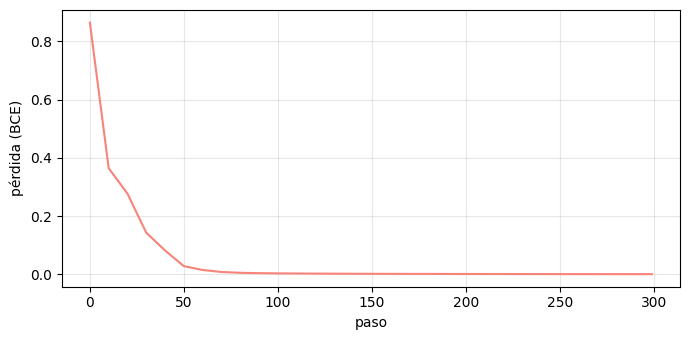

In [6]:
cnn.fijar_semilla(SEMILLA)
h_lote = cnn.sobreajustar_lote(cnn.CNNPlana(L=L).to(DISP), x, y, cnn.perdida_bce, DISP, pasos=300)
print(h_lote.iloc[[0, 5, 10, -1]].to_string(index=False))
assert h_lote.errores.iloc[-1] == 0, "No logra sobreajustar un lote: revisar antes de entrenar"

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(h_lote.paso, h_lote.perdida, color=ROL["umbral"])
ax.set_xlabel("paso"); ax.set_ylabel("pérdida (BCE)"); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(RUTA_SAL / "img-sobreajuste_lote.png", dpi=150)

### 3.1 Por qué BCE y no CSI suave (decisión 2)

La primera corrida de esta prueba usó la CSI suave, la pérdida propuesta en el borrador (4.4). Resultado (lote de 256 pares, semilla 42, 14-oct-2026): errores 197 → 5 (paso 100) → 3 (paso 300) → 3 (paso 999); con BCE, 197 → 0 ya en el paso 100. En el lote no hay pares con entrada casi igual y etiqueta opuesta (distancia < 10 % de la mediana: 0 pares), así que el lote es separable y el estancamiento es de la pérdida, no de los datos.

Causa: la CSI suave se calcula sobre p = sigmoid(logit). Si la red está segura y equivocada en un par (p ≈ 0 en un positivo), la sigmoide está saturada y el gradiente que llega a ese par es prácticamente cero. En el entrenamiento real serían justamente los positivos difíciles los que dejarían de aprender. La BCE con logits tiene gradiente p − y, máximo en esos casos.

La celda siguiente reproduce la comparación (≈ 30 s en la GPU).

In [ ]:
cnn.fijar_semilla(SEMILLA)
h_csi = cnn.sobreajustar_lote(cnn.CNNPlana(L=L).to(DISP), x, y, cnn.perdida_csi, DISP, pasos=1000)
cnn.fijar_semilla(SEMILLA)
h_bce = cnn.sobreajustar_lote(cnn.CNNPlana(L=L).to(DISP), x, y, cnn.perdida_bce, DISP, pasos=1000)
pd.DataFrame({"CSI suave": h_csi.set_index("paso").errores, "BCE": h_bce.set_index("paso").errores}).loc[[0, 100, 300, 500, 999]]

## 4. Entrenamiento

Configuración de las decisiones 2–6. Se guarda el estado con mayor PR-AUC de validación en `salidas_18/cnn_plana_L2.pt`. Cada validación se registra en MLflow (pérdidas, PR-AUC, AUC, CSI máximo y su umbral).

In [7]:
CFG = dict(L=L, canales=(32, 64, 128), dropout=0.3, perdida="bce", lr=1e-3, weight_decay=1e-4,
           tam_lote=256, n_dificiles=2, n_aleatorios=2, criterios="red_activa+casi_positivo",
           max_epocas=200, validar_cada=5, paciencia=8, semilla=SEMILLA)
RUTA_MODELO = RUTA_SAL / f"cnn_plana_L{L}.pt"
NOMBRE = f"cnn_plana_L{L}"

cnn.fijar_semilla(SEMILLA)
modelo = cnn.CNNPlana(L=L, canales=CFG["canales"], dropout=CFG["dropout"]).to(DISP)
t0 = time.time()
if MLFLOW:
    with mlflow.start_run(run_name=NOMBRE) as corrida:
        mlflow.log_params({k: str(v) for k, v in CFG.items()} | {"parametros": cnn.n_parametros(modelo)})
        hist = cnn.entrenar(modelo, dl_tr, mu, dl_val, y_val, CFG, DISP, RUTA_MODELO,
                            registrar=lambda m, paso: mlflow.log_metrics(m, step=paso))
        ID_CORRIDA = corrida.info.run_id
else:
    hist = cnn.entrenar(modelo, dl_tr, mu, dl_val, y_val, CFG, DISP, RUTA_MODELO)
hist.to_csv(RUTA_SAL / f"historial_{NOMBRE}.csv", index=False)
print(f"Entrenamiento: {(time.time() - t0) / 60:.1f} min, {hist.epoca.max()} épocas")

c:\Users\diani\Documents\repositories\nowcasting-bogota\src\cnn.py:179: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:821.)
  total += float(l) * len(y)


época   5 | pérdida train 0.3045 val 0.0872 | PR-AUC 0.0244 AUC 0.845 CSI máx 0.0315 | 4+50 s  ← mejor
época  10 | pérdida train 0.2337 val 0.0346 | PR-AUC 0.0225 AUC 0.853 CSI máx 0.0276 | 4+48 s
época  15 | pérdida train 0.1930 val 0.0693 | PR-AUC 0.0173 AUC 0.795 CSI máx 0.0232 | 4+50 s
época  20 | pérdida train 0.1596 val 0.0408 | PR-AUC 0.0173 AUC 0.821 CSI máx 0.0202 | 4+50 s
época  25 | pérdida train 0.1303 val 0.0375 | PR-AUC 0.0173 AUC 0.822 CSI máx 0.0223 | 4+50 s
época  30 | pérdida train 0.1090 val 0.0394 | PR-AUC 0.0172 AUC 0.809 CSI máx 0.0210 | 4+50 s
época  35 | pérdida train 0.0935 val 0.0476 | PR-AUC 0.0150 AUC 0.794 CSI máx 0.0175 | 4+50 s
época  40 | pérdida train 0.0848 val 0.0482 | PR-AUC 0.0117 AUC 0.757 CSI máx 0.0114 | 4+50 s
época  45 | pérdida train 0.0708 val 0.0456 | PR-AUC 0.0148 AUC 0.816 CSI máx 0.0156 | 4+50 s
Parada temprana: 8 validaciones sin mejorar el PR-AUC.
Entrenamiento: 10.8 min, 45 épocas


## 5. Curvas de entrenamiento

Pérdida de train y de validación (BCE; no son comparables entre sí: train tiene 20 % de positivos por el muestreo 1:2:2 y validación la proporción real, 0.46 %, por eso la de validación es menor; importa su tendencia), y las métricas de validación por época validada. Qué mirar: si la pérdida de validación sube mientras la de train baja (sobreajuste), y cuánto oscilan el PR-AUC y el CSI máximo entre validaciones (la estabilidad que en S5 no se pudo evaluar). La línea vertical marca la época elegida.

Época elegida: 5


,epoca,val_pr_auc,val_auc,val_csi_max,val_umbral
mean,25.0000,0.0175,0.8124,0.0211,0.1844
std,13.6931,0.0039,0.0288,0.0061,0.2290
min,5.0000,0.0117,0.7574,0.0114,0.0100
max,45.0000,0.0244,0.8534,0.0315,0.5800


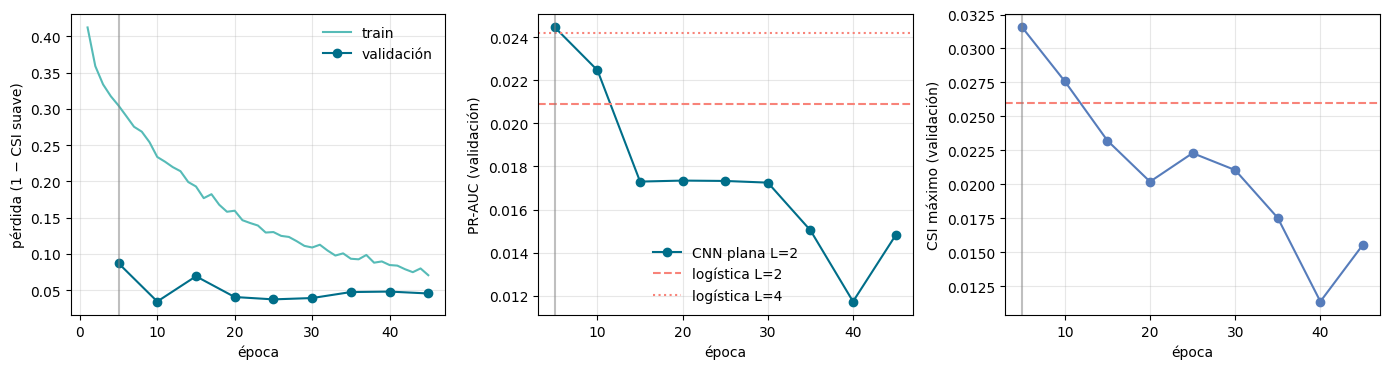

In [8]:
if "hist" not in globals():
    hist = pd.read_csv(RUTA_SAL / f"historial_cnn_plana_L{L}.csv")
hv = hist.dropna(subset=["val_pr_auc"])
e_mejor = int(hv.loc[hv.val_pr_auc.idxmax(), "epoca"])
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
axs[0].plot(hist.epoca, hist.train_perdida, color=PALETA["wi-iceblue"], label="train")
axs[0].plot(hv.epoca, hv.val_perdida, "o-", color=PALETA["wwu-blue"], label="validación")
axs[0].set_ylabel("pérdida (BCE)"); axs[0].legend(frameon=False)
axs[1].plot(hv.epoca, hv.val_pr_auc, "o-", color=PALETA["wwu-blue"], label="CNN plana L=2")
axs[1].axhline(0.0209, ls="--", color=ROL["umbral"], label="logística L=2")
axs[1].axhline(0.0242, ls=":", color=ROL["umbral"], label="logística L=4")
axs[1].set_ylabel("PR-AUC (validación)"); axs[1].legend(frameon=False)
axs[2].plot(hv.epoca, hv.val_csi_max, "o-", color=PALETA["wi-darkblue"])
axs[2].axhline(0.026, ls="--", color=ROL["umbral"])
axs[2].set_ylabel("CSI máximo (validación)")
for a in axs:
    a.axvline(e_mejor, color="grey", alpha=0.5); a.set_xlabel("época"); a.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(RUTA_SAL / "img-curvas_entrenamiento.png", dpi=150)
print(f"Época elegida: {e_mejor}")
hv[["epoca", "val_pr_auc", "val_auc", "val_csi_max", "val_umbral"]].describe().loc[["mean", "std", "min", "max"]].round(4)

## 6. Evaluación en validación

Con el modelo de la época elegida: predicciones de validación, umbral de decisión por CSI (decisión 4 de S4a) y evaluación completa con bootstrap de días pluviométricos. Mismas funciones y salidas que en 17, para que las tablas sean comparables.

In [9]:
ck = cnn.cargar_mejor(modelo, RUTA_MODELO, DISP)
p3 = cnn.predecir(modelo, dl_val, DISP)
print(f"época {ck['epoca']}, PR-AUC guardado {ck['val_pr_auc']:.4f}, recalculado {ev.auc_pr(y_val, p3)[1]:.4f}")
assert abs(ev.auc_pr(y_val, p3)[1] - ck["val_pr_auc"]) < 1e-6, "Las predicciones no reproducen el PR-AUC guardado"

def evaluar_val(nombre, p, extra=None):
    sel = ev.elegir_umbral(y_val, p)
    planas, art = ev.evaluar(val.timestamp, y_val, p, sel["umbral"], conjunto="val", B=B, semilla=SEMILLA)
    planas["val_csi_meseta_desde"], planas["val_csi_meseta_hasta"] = sel["meseta_desde"], sel["meseta_hasta"]
    sel["curva"].to_csv(RUTA_SAL / f"curva_{nombre}.csv", index=False)
    pd.DataFrame({"codigoestacion": val.codigoestacion, "timestamp": val.timestamp,
                  "etiqueta": y_val, "p": p}).to_parquet(RUTA_SAL / f"pred_val_{nombre}.parquet")
    if MLFLOW:
        with mlflow.start_run(run_id=ID_CORRIDA):
            mlflow.log_metrics({f"final_{k}": float(v) for k, v in planas.items() if np.isfinite(v)})
            mlflow.log_artifact(str(RUTA_SAL / f"curva_{nombre}.csv"))
            mlflow.log_artifact(str(RUTA_MODELO))
    return sel, planas

def resumen(planas):
    k = ["umbral", "csi", "pod", "far", "ets", "auc", "pr_auc"]
    out = {m: planas[f"val_{m}"] for m in k}
    for m in k[1:]:
        out[f"{m}_ic"] = f"[{planas[f'val_{m}_ic_inf']:.3f}, {planas[f'val_{m}_ic_sup']:.3f}]"
    out["n_alertas"] = planas["val_n_alertas"]
    return out

sel3, planas3 = evaluar_val(NOMBRE, p3, {"L": L})
pd.Series(resumen(planas3))

época 5, PR-AUC guardado 0.0244, recalculado 0.0244


umbral                 0.58
csi                0.031549
pod                0.110962
far                0.957779
ets                0.028231
auc                0.845408
pr_auc              0.02445
csi_ic       [0.011, 0.043]
pod_ic       [0.034, 0.199]
far_ic       [0.937, 0.984]
ets_ic       [0.009, 0.038]
auc_ic       [0.796, 0.878]
pr_auc_ic    [0.011, 0.038]
n_alertas              3908
dtype: object

### 6.1 Frente a las referencias

Puntuales de las referencias recalculados desde sus predicciones guardadas (los intervalos están en 17). Comparaciones pareadas de CSI, con los mismos días sorteados para los dos modelos de cada par (decisión 3 de S4a): la de la escalera es **CNN plana L = 2 − logística L = 2** (mismo L, cambia solo la estructura espacial); **CNN plana − umbral** responde la pregunta central.

In [10]:
filas = []
p_ref = {"1 · umbral C13": ref["peldano1_umbral_c13"].p.to_numpy(),
         "2 · logística L=2": ref["peldano2_logistica_L2"].p.to_numpy(),
         "2 · logística L=4": ref["peldano2_logistica_L4"].p.to_numpy(),
         f"3 · CNN plana L={L}": p3}
for nombre, p in p_ref.items():
    s = ev.elegir_umbral(y_val, p)
    a, b, c, d = ev.tabla_contingencia(y_val, p, s["umbral"])
    m = ev.metricas(a, b, c, d)
    auc, ap = ev.auc_pr(y_val, p)
    filas.append({"modelo": nombre, "PR-AUC": ap, "AUC": auc, "CSI": m["csi"], "POD": m["pod"], "FAR": m["far"],
                  "umbral": s["umbral"], "alertas": a + b})
pd.DataFrame(filas).set_index("modelo").round(4)

,PR-AUC,AUC,CSI,POD,FAR,umbral,alertas
modelo,,,,,,,
1 · umbral C13,0.0192,0.7761,0.0243,0.0330,0.9149,0.36,576
2 · logística L=2,0.0209,0.8234,0.0260,0.0740,0.9615,0.41,2855
2 · logística L=4,0.0242,0.8158,0.0284,0.0471,0.9331,0.48,1046
3 · CNN plana L=2,0.0244,0.8454,0.0315,0.1110,0.9578,0.58,3908


In [11]:
bl, t3 = ev.tablas_por_bloque(val.timestamp, y_val, p3, sel3["umbral"])
pesos = ev.pesos_bootstrap(len(bl), B=B, semilla=SEMILLA)
filas = []
for nombre in ("2 · logística L=2", "1 · umbral C13"):
    p = p_ref[nombre]
    _, t_ref = ev.tablas_por_bloque(val.timestamp, y_val, p, ev.elegir_umbral(y_val, p)["umbral"], bloques=bl)
    c = ev.comparar_pareado(t3, t_ref, pesos)
    filas.append({"comparación": f"CNN plana L={L} − {nombre[4:]}", "ΔCSI": round(c["delta"], 4),
                  "IC 95 %": f"[{c['ic_inf']:.4f}, {c['ic_sup']:.4f}]", "gana la CNN": f"{c['frac_gana_A']:.1%}"})
pd.DataFrame(filas)

,comparación,ΔCSI,IC 95 %,gana la CNN
0,CNN plana L=2 − logística L=2,0.0056,"[-0.0101, 0.0201]",75.3%
1,CNN plana L=2 − umbral C13,0.0072,"[-0.0088, 0.0343]",79.7%


## 7. Métricas por evento y estratos

Como en 17, Sección 7: episodios de validación desde las etiquetas y los umbrales operativos; estratos noche (19:00–06:59 local), terciles de umbral, temporada y nube fría. Pregunta clave de este peldaño: ¿la CNN acierta de día, donde el umbral sobre C13 no acertó nada y la logística muy poco (CSI 0.013)?

In [12]:
etiquetas_gt = pd.read_parquet(RAIZ / "data_ingestion" / "ground_truth" / "etiquetas_ground_truth.parquet")
lab = etiquetas_gt.assign(codigoestacion=etiquetas_gt.codigoestacion.astype(str))
lab = lab[lab.codigoestacion != NG]
umb = pd.read_csv(RAIZ / "data_ingestion" / "ground_truth" / "umbral_operativo_por_estacion.csv",
                  dtype={"codigoestacion": str}).set_index("codigoestacion")["umbral_mm_h"]
umb = umb[umb.index.isin(lab.codigoestacion.unique())]
episodios, fuertes = ev.episodios_lluvia(lab, umb)
val["id_episodio"], _ = ev.asignar_episodio(val, fuertes)
assert ((val.id_episodio >= 0) == (val.etiqueta == 1)).all(), "Asignación de episodios inconsistente con las etiquetas"
grupo_umbral, cortes = ev.terciles_umbral(umb)
p10_par = val.set_index(["codigoestacion", "timestamp"])["p10_c13"]

def estratos_modelo(p, nombre):
    u = ev.elegir_umbral(y_val, p)["umbral"]
    pares = val.assign(y=y_val, p=p)
    ep, av = ev.eventos(pares, episodios, u)
    bl, _ = ev.tablas_por_bloque(val.timestamp, y_val, p, u)
    pesos = ev.pesos_bootstrap(len(bl), B=B, semilla=SEMILLA)
    args = dict(pares=pares, ep=ep, avisos=av, umbral=u, pesos=pesos, bloques=bl)
    clave = lambda est_, t: pd.MultiIndex.from_arrays([est_, t])
    particiones = {
        "total":     (np.full(len(val), "total"), np.full(len(ep), "total"), np.full(len(av), "total")),
        "noche":     (ev.es_noche(val.timestamp), ev.es_noche(ep.inicio), ev.es_noche(av.t_primera)),
        "umbral":    (val.codigoestacion.map(grupo_umbral).to_numpy(), ep.codigoestacion.map(grupo_umbral).to_numpy(),
                      av.codigoestacion.map(grupo_umbral).to_numpy()),
        "temporada": (ev.temporada(val.timestamp), ev.temporada(ep.inicio), ev.temporada(av.t_primera)),
        "nube_fria": (ev.nube_fria(val.p10_c13), ev.nube_fria(p10_par.reindex(clave(ep.codigoestacion, ep.t_primer_par)).to_numpy()),
                      ev.nube_fria(p10_par.reindex(clave(av.codigoestacion, av.t_primera)).to_numpy())),
    }
    out = pd.concat([ev.evaluar_por_estrato(**args, estrato_pares=sp, estrato_ep=se, estrato_avisos=sa).assign(particion=k)
                     for k, (sp, se, sa) in particiones.items()], ignore_index=True)
    out.to_csv(RUTA_SAL / f"estratos_{nombre}.csv", index=False)
    return out, ev.resumen_anticipacion(ep)

est3, ant3 = estratos_modelo(p3, NOMBRE)
print("Anticipación, CNN plana:", {k: round(v, 2) for k, v in ant3.items()})
cols = ["particion", "estrato", "n_tormentas", "n_episodios", "csi", "pod_evento", "far_evento", "frac_anticipacion_1h"]
est3[cols].round(3)

Anticipación, CNN plana: {'n_avisados': 45, 'mediana_h': 2.17, 'q1_h': 1.83, 'q3_h': 2.67, 'frac_1h': 0.98}


,particion,estrato,n_tormentas,n_episodios,csi,pod_evento,far_evento,frac_anticipacion_1h
0,total,total,1487,149,0.032,0.30201342281879195,0.9477124183006536,0.9777777777777777
1,noche,False,888,72,0.040,0.5277777777777778,0.9338709677419355,0.9736842105263158
2,noche,True,599,77,0.014,0.09090909090909091,0.9765100671140939,1.0
3,umbral,alto,550,51,0.048,0.5294117647058824,0.9166666666666666,1.0
4,umbral,bajo,423,48,0.023,0.20833333333333334,0.9683098591549296,0.9
5,umbral,medio,514,50,0.018,0.16,0.9671532846715328,1.0
6,temporada,DEF,383,36,0.014,0.2222222222222222,0.9753086419753086,1.0
7,temporada,SON,1104,113,0.040,0.3274336283185841,0.9326599326599326,0.972972972972973
8,nube_fria,False,1107,117,0.035,0.36752136752136755,0.9445129469790382,0.9767441860465116
9,nube_fria,True,380,32,0.010,0.0625,0.9719626168224299,1.0


In [ ]:
# Comparación por estrato con las referencias de 17 (CSI por pares y POD por evento).
# Se lee desde los CSV guardados; "estrato" se pasa a texto en las dos tablas (en memoria noche y nube_fria
# son booleanos y en los CSV texto: sin esto el cruce perdía esas filas).
def leer_estratos(ruta, etiqueta):
    r = pd.read_csv(ruta)[["particion", "estrato", "csi", "pod_evento"]]
    r["estrato"] = r["estrato"].astype(str)
    return r.rename(columns={"csi": f"csi · {etiqueta}", "pod_evento": f"pod_ev · {etiqueta}"})

comp = leer_estratos(RUTA_SAL / f"estratos_cnn_plana_L{L}.csv", "CNN")
for arch, et in (("estratos_peldano1.csv", "umbral"), ("estratos_peldano2_L4.csv", "logística L=4")):
    comp = comp.merge(leer_estratos(RUTA_17 / arch, et), on=["particion", "estrato"], how="left")
comp.round(3)

## 8. Sensibilidad al largo del bloque y estabilidad del umbral

Las dos pruebas que en S5 no fueron concluyentes por los pocos aciertos (Secciones 8 y 9 de 17), repetidas con las predicciones de la CNN. Regla fijada en S4a: si el ancho del IC del CSI sigue creciendo de 24 a 48 h, se pasa a bloques de 48 h.

In [14]:
filas = []
for h in (6, 12, 24, 48):
    pl, _ = ev.evaluar(val.timestamp, y_val, p3, sel3["umbral"], conjunto="val", B=B, semilla=SEMILLA,
                       horas_bloque=h, con_auc=False)
    filas.append({"horas_bloque": h, "n_bloques": pl["val_n_bloques"], "ancho_ic_csi": pl["val_csi_ic_sup"] - pl["val_csi_ic_inf"]})
sens = pd.DataFrame(filas)
sens.to_csv(RUTA_SAL / "sensibilidad_bloque.csv", index=False)
print(sens.round(4).to_string(index=False))

bl_u, t_bu = ev.tablas_por_bloque_y_umbral(val.timestamp, y_val, p3)
u_rep = ev.estabilidad_umbral(t_bu, ev.pesos_bootstrap(len(bl_u), B=1000, semilla=SEMILLA))
q = np.quantile(u_rep, [0.025, 0.5, 0.975])
print(f"\nUmbral elegido {sel3['umbral']:.2f}; re-elegido en 1,000 réplicas: mediana {q[1]:.2f}, 95 % central [{q[0]:.2f}, {q[2]:.2f}]")

 horas_bloque  n_bloques  ancho_ic_csi
            6        189        0.0312
           12         95        0.0361
           24         48        0.0317
           48         25        0.0365

Umbral elegido 0.58; re-elegido en 1,000 réplicas: mediana 0.47, 95 % central [0.36, 0.69]


## 9. Conclusiones

**Circuito.** El sobreajuste de un lote pasa con BCE (0 errores en 100 pasos); con CSI suave se estanca (Sección 3.1), lo que cambia la decisión 2. La corrida entrenó 45 épocas en 10.8 min (≈ 4 s por época de train, ≈ 50 s por validación) y se detuvo por paciencia; el modelo guardado reproduce exactamente el PR-AUC registrado.

**Sobreajuste temprano.** La mejor época fue la 5, la primera validada: desde ahí el PR-AUC de validación cae casi sin pausa (0.024 → 0.023 → 0.017 → … → 0.012 en la época 40) mientras la pérdida de train sigue bajando (0.30 → 0.07). Cada época reusa los mismos 4,249 positivos y la red los memoriza. Dos consecuencias para S7: (1) el óptimo puede estar antes de la época 5 y no se vio: validar **cada época** al menos al principio; (2) la búsqueda tiene que incluir lo que frena el sobreajuste: tasa de aprendizaje menor, más dropout y decaimiento de pesos, y más negativos por época.

**Frente a las referencias (validación).** La CNN plana L = 2 tiene el mayor PR-AUC (0.0244 [0.011, 0.038], a la par de la logística L = 4, 0.0242, que usa el doble de historia), el mayor AUC (0.845 [0.796, 0.878] frente a 0.823 de la logística L = 2) y el mayor CSI (0.032 [0.011, 0.043]; POD 0.11, FAR 0.96, umbral 0.58). Las comparaciones pareadas de CSI no son significativas: frente a la logística L = 2, ΔCSI 0.006 [−0.010, 0.020] (gana en 75 % de las réplicas); frente al umbral, 0.007 [−0.009, 0.034] (80 %). **Por evento la diferencia es más clara:** avisa 45 de 149 episodios (POD por evento 0.30) frente a 23 de la logística L = 4 (0.15) y 13 del umbral (0.09), con anticipación mediana de 2.2 h (cuartiles 1.8–2.7 h); a cambio emite más alertas (FAR por evento 0.95).

**Estratos: acierta de día, al revés que las referencias.** CSI de día 0.040 y de noche 0.014; POD por evento de día 0.53 y de noche 0.09. Sin nube fría 0.035, con nube fría 0.010. El umbral sobre C13 solo acertaba de noche y con nubes muy frías (sistemas maduros); la CNN capta la convección diurna en desarrollo, antes de que haya nubes frías, que es el régimen dominante de la Sabana (pico a las 14–15 h, Casallas-García et al., 2023). Que falle de noche es coherente con el cambio de régimen entre entrenamiento y validación (17.5 % frente a 42.4 % de positivos nocturnos): la red aprendió sobre todo el régimen diurno de 2024. Hallazgo para Resultados y Discusión; también indica que la selección en esta validación favorece a modelos buenos de noche, que es lo que la red hace peor (decisión 8).

**Largo del bloque.** Ancho del IC del CSI: 0.031 (6 h), 0.036 (12 h), 0.032 (24 h), 0.037 (48 h). El ancho sube de 24 a 48 h, pero sin tendencia sostenida (baja de 12 a 24 h): oscila ±0.003 alrededor de 0.034. Se interpreta que la regla de S4a ("si el ancho *sigue creciendo* de 24 a 48 h") pedía una tendencia y no se cumple: **se mantiene el día pluviométrico de 24 h** (decisión de Diana, 14-oct-2026). Se revisa de nuevo con las predicciones de S7.

**Umbral de decisión.** Elegido 0.58; re-elegido en 1,000 réplicas: mediana 0.47, 95 % central [0.36, 0.69]. Sigue siendo inestable, menos que el de la logística ([0.18, 0.53]).

**Para S7.** Validar cada época (o cada época en las primeras ~15) y bajar el máximo de épocas; espacio de búsqueda con tasa de aprendizaje (incluir 10⁻⁴ y 3·10⁻⁴), dropout, decaimiento de pesos, proporción de negativos y bolsa difícil; pérdida BCE frente a BCE + CSI. La decisión 8 (validación atípica) se mantiene por ahora: el plan B (validación cruzada temporal dentro de 2024) se activa si en S7 el mejor punto resulta muy inestable entre configuraciones parecidas.